In [1]:
import os

import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from skimage import filters
from scipy import stats
from sklearn.cluster import KMeans

In [44]:
mesh_database_path = r"../99_broccoli_models"

mesh_db = []
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db.append(os.path.join(mesh_database_path, file))


def mesh2pcd(mesh):
    mesh_pcd = o3d.geometry.PointCloud()
    mesh_pcd.points = mesh.vertices
    mesh_pcd.colors = mesh.vertex_colors
    mesh_pcd.normals = mesh.vertex_normals
    
    return mesh_pcd

def project_points_on_vector(points, vector):
    """
    把点投影到给定向量上
    输入：points: nx3的三维点
         vector: 1x3的向量
    输出：投影后的点(在空间中的位置)
    """
    v_norm = np.sqrt(sum(vector**2))
    
    return (np.dot(points, vector.reshape(3,1))/v_norm**2)*vector


def segment_crown(head_pcd, denoise_count=20, denoise_radius=0.01, show_log=False):
    # 计算定向边界框
    obb = head_pcd.get_oriented_bounding_box()
    # find the maximum edge and its vector:
    main_idx = np.argmax(obb.extent)

    # 把点云投影到最长轴上
    # pcd_on_z -> (x, y, z) 3D
    pcd_on_z = project_points_on_vector(np.asarray(head_pcd.points), obb.R[:,main_idx])
    # project 3D line to 1D
    pcd_on_z_unit = (pcd_on_z / obb.R[:,main_idx])[:,0]

    # use Kmeans to classify points to 2 class by color
    rgb = np.asarray(head_pcd.colors)
    kmeans = KMeans(n_clusters=2, random_state=0, n_init="auto")
    kmeans.fit(rgb)

    ## the z axis points of each class
    z0 = pcd_on_z_unit[kmeans.labels_ == 0]
    z1 = pcd_on_z_unit[kmeans.labels_ == 1]
    z0_mean = z0.mean()
    z1_mean = z1.mean()

    # find out which is the crown class
    ## calculate the direction
    pmax = pcd_on_z_unit.max()
    pmin = pcd_on_z_unit.min()
    pmid = (pmax + pmin) / 2
    pmean = pcd_on_z_unit.mean()

    if pmean < pmid:
        # The crown is in the -z direction (points KDE line)
        #
        # |        pmean
        # |       . |    pmid
        # |     .   |  . ||
        # |   .     |    ||  .  
        # | .       |    ||       ^   .
        # o-------------------------------> +z
        
        # vz is the crown Z direction vertex
        vz = obb.R[:,main_idx] * -1
        if z0_mean < z1_mean:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0
        else:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
    else:
        # The crown is in the +z direction (points KDE line)
        #
        # |                 pmean
        # |            pmid   |  .
        # |             ||  . |    .
        # |           . ||    |      .
        # | .     ^     ||    |        .
        # o-------------------------------> +z
        
        # vz is the crown Z direction vertex
        vz = obb.R[:,main_idx]
        if z0_mean < z1_mean:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
        else:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0

    crown_int_idx = np.where(crown_bool_idx)[0]

    crown_pcd = head_pcd.select_by_index(crown_int_idx)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_radius_outlier(denoise_count, denoise_radius)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_statistical_outlier(denoise_count, denoise_radius)
    crown_pcd_denoised, keeped_int_idx = remove_dbscan_outlier(crown_pcd, denoise_count, denoise_radius, show_log)
    crown_denoised_int_idx = crown_int_idx[keeped_int_idx]

    ## create a results pcd, 
    labeled_pcd = o3d.geometry.PointCloud()

    ### black for stem
    label_rgb = np.zeros((len(head_pcd.points), 3))
    ### red for denoised
    label_rgb[crown_bool_idx, :] = np.array([1,0,0])
    ### green for crown
    label_rgb[crown_denoised_int_idx,:] = np.array([0,1,0])

    labeled_pcd.points = o3d.utility.Vector3dVector(head_pcd.points)
    labeled_pcd.colors = o3d.utility.Vector3dVector(label_rgb)

    #################
    ## draw figures
    #################
    if show_log:
        kde0 = stats.gaussian_kde(z0)
        xx0 = np.linspace(pmin, pmax, 1000)
        yy0 = kde0(xx0)

        kde1 = stats.gaussian_kde(z1)
        xx1 = np.linspace(pmin, pmax, 1000)
        yy1 = kde1(xx1)

        fig, ax = plt.subplots(1,1)
        ax.plot(xx0, yy0,color='b', label='z0')
        ax.plot(xx1, yy1,color='g', label='z1')

        ax.axvline(x=pmid, color='r', label="middle")

        ax.axvline(x=z0_mean, color='b', label="z0mean")
        ax.axvline(x=z1_mean, color='g',label="z1mean")

        plt.legend()
        plt.show()

    return crown_pcd_denoised, labeled_pcd, crown_denoised_int_idx, vz

In [46]:
def remove_dbscan_outlier(pcd, min_points, eps, show_log=False):
    label = pcd.cluster_dbscan(eps=eps, min_points=min_points, print_progress=True)
    db_labels, db_count = np.unique(label, return_counts=True)

    if len(db_count) <= 2:  # already splited by [-1 ,0]
        plant_cluster_idx = [0]
    else:
        # calculate the cluster size as another reference
        characters = np.empty((len(db_count), 2))
        for i, (l, c) in enumerate(zip(db_labels, db_count)):
            idx_on_label = np.where(label==l)[0]
            pcd_on_label = pcd.select_by_index(idx_on_label)
            volume = _calculate_xyz_volume(pcd_on_label)

            characters[i-1, 0] = c
            characters[i-1, 1] = volume

        # print("charectors:\n",characters)
        # Kmeans cluster
        km = KMeans(n_clusters=2)
        km.fit(characters)

        class0 = characters[km.labels_ == 0, :]
        class1 = characters[km.labels_ == 1, :]

        # print("class0, class1\n", class0, '\n', class1)
        # find the class label with largest point clouds (plants)
        if class0.mean(axis=0)[0] > class1.mean(axis=0)[0]:
            plant_cluster_idx = np.where(km.labels_ == 0)[0]
        else:
            plant_cluster_idx = np.where(km.labels_ == 1)[0]

        if show_log: print(f"DBSCAN\nlabel - count\n{np.vstack([db_labels, db_count]).T}\nUse {plant_cluster_idx} as plants")
        plant_id = []
        for idx in plant_cluster_idx:
            # print(idx, label, np.where(np.array(label)==idx)[0])
            plant_id += np.where(np.array(label)==idx)[0].tolist()

        # print("plant_id\n", plant_id)

        return pcd.select_by_index(plant_id), plant_id

def _calculate_xyz_volume(pcd):
    pcd_xyz = np.asarray(pcd.points)

    x_len = pcd_xyz[:, 0].max() - pcd_xyz[:, 0].min()
    y_len = pcd_xyz[:, 1].max() - pcd_xyz[:, 1].min()
    z_len = pcd_xyz[:, 2].max() - pcd_xyz[:, 2].min()

    return x_len * y_len * z_len

/Users/hwang/anaconda/miniconda3/envs/lab/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


DBSCAN
label - count
[[   -1   116]
 [    0 42056]
 [    1    87]
 [    2    14]
 [    3    23]
 [    4    33]
 [    5    28]
 [    6    17]
 [    7    13]
 [    8    12]
 [    9    43]
 [   10    18]
 [   11    10]
 [   12    17]
 [   13   170]
 [   14    16]
 [   15    21]
 [   16    67]
 [   17    22]
 [   18    12]]
Use [0] as plants


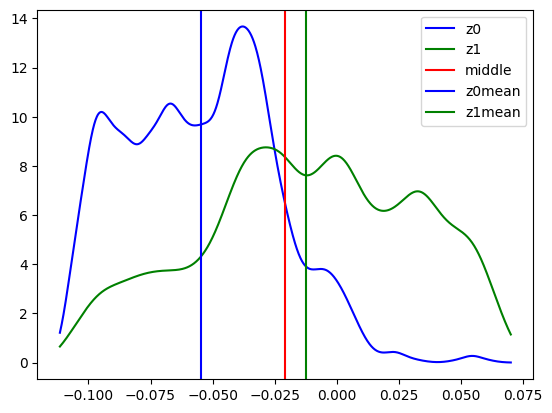

In [16]:
def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(mesh_db[190]))

crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005)

o3d.visualization.draw_geometries([crown_pcd])

In [12]:
obb = crown_pcd.get_oriented_bounding_box()
obb.color = (0,0,0)

# 矩阵的正交方向
ur_set = o3d.geometry.LineSet()
ur_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0], obb.R[:,0]/10, obb.R[:,1]/10, obb.R[:,2]/10]))
ur_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
ur_set.colors = o3d.utility.Vector3dVector(np.array([[1,1,0],[0,1,1],[1,0,1]]))

o3d.visualization.draw_geometries([crown_colored_pcd, obb, ur_set])

In [13]:
obb.R[:,0]

array([ 0.46479375,  0.26970908, -0.84334085])

In [14]:
def angle2(v1, v2):
    x=np.array(v1)
    y=np.array(v2)

    # 分别计算两个向量的模：
    module_x=np.sqrt(x.dot(x))
    module_y=np.sqrt(y.dot(y))

    # 计算两个向量的点积
    dot_value=x.dot(y)

    # 计算夹角的cos值：
    cos_theta=dot_value/(module_x*module_y)

    # 求得夹角（弧度制）：
    angle_radian=np.arccos(cos_theta)

    # 转换为角度值：
    angle_value=angle_radian*180/np.pi
    return angle_value

find the minimun ange

In [23]:
clamp_angle_sin = []
for i in range(0, 3):
    angle = angle2(vz, obb.R[:, i])
    clamp_angle_sin.append(np.sin(np.deg2rad(angle)))

main_idx = np.argmin(np.asarray(clamp_angle_sin))

main_direction = obb.R[:, main_idx]

rotate to this direction

In [26]:
def get_unit_vector(v):
    return v / np.linalg.norm(v)

def get_rotation_matrix(a, b):
    v = np.cross(a, b)
    s = np.dot(a, b)
    vx = np.array([[0, -v[2], v[1]],
                   [v[2], 0, -v[0]],
                   [-v[1], v[0], 0]])
    R = np.identity(3) + vx + np.dot(vx, vx) * (1 / (1 + s))

    return R

In [28]:
rotation_matrix = get_rotation_matrix(get_unit_vector(main_direction), (0,0,1))
rotation_matrix

array([[ 0.97189947,  0.14671256,  0.18408378],
       [ 0.14671256,  0.23401522, -0.96109953],
       [-0.18408378,  0.96109953,  0.2059147 ]])

In [29]:
# 坐标轴 RGB -> XYZ
line_set = o3d.geometry.LineSet()
line_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0],[0.1,0,0],[0,0.1,0], [0,0,0.1]]))
line_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
line_set.colors = o3d.utility.Vector3dVector(np.array([[1,0,0],[0,1,0],[0,0,1]]))

In [31]:
pcd_rotated = crown_colored_pcd.rotate(rotation_matrix, center=obb.center)

In [32]:
o3d.visualization.draw_geometries([pcd_rotated, line_set])

In [69]:
def rotate_to_z(crown_pcd, original_pcd, vz):
    obb = crown_pcd.get_oriented_bounding_box()
    
    # find out the closest vector to orginal broccoli longest axis
    clamp_angle_sin = []
    for i in range(0, 3):
        angle = angle2(vz, obb.R[:, i])
        clamp_angle_sin.append(np.sin(np.deg2rad(angle)))

    main_idx = np.argmin(np.asarray(clamp_angle_sin))
    main_direction = obb.R[:, main_idx]

    R = get_rotation_matrix(get_unit_vector(main_direction), (0,0,1))
    pcd_rotated = copy(original_pcd).rotate(R, center=obb.center)

    return pcd_rotated


def angle2(v1, v2):
    x=np.array(v1)
    y=np.array(v2)

    # 分别计算两个向量的模：
    module_x=np.sqrt(x.dot(x))
    module_y=np.sqrt(y.dot(y))

    # 计算两个向量的点积
    dot_value=x.dot(y)

    # 计算夹角的cos值：
    cos_theta=dot_value/(module_x*module_y)

    # 求得夹角（弧度制）：
    angle_radian=np.arccos(cos_theta)

    # 转换为角度值：
    angle_value=angle_radian*180/np.pi
    return angle_value

def get_unit_vector(v):
    return v / np.linalg.norm(v)

def get_rotation_matrix(a, b):
    v = np.cross(a, b)
    s = np.dot(a, b)
    vx = np.array([[0, -v[2], v[1]],
                   [v[2], 0, -v[0]],
                   [-v[1], v[0], 0]])
    R = np.identity(3) + vx + np.dot(vx, vx) * (1 / (1 + s))

    return R

visualize the output final point cloud

In [68]:
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
from copy import copy

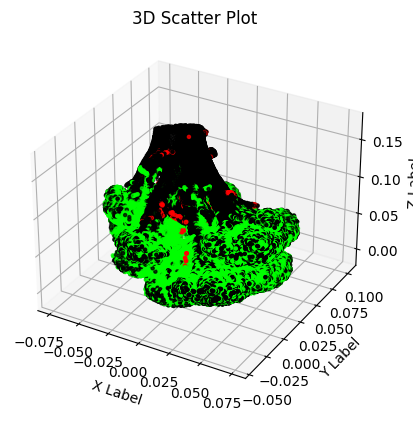

In [38]:
# crown_pcd, crown_colored_pcd, crown_points_index, vz 
rotated_pcd = rotate_to_z(crown_pcd, def_test_pcd, vz)

xyz = np.asarray(rotated_pcd.points)
rgb = np.asarray(crown_colored_pcd.colors)

fig = plt.figure()
ax = plt.axes(projection='3d')

ax.scatter(*xyz.T, c=rgb, marker='.')

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')
ax.set_title('3D Scatter Plot')

plt.show()

summary demo

/Users/hwang/anaconda/miniconda3/envs/lab/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


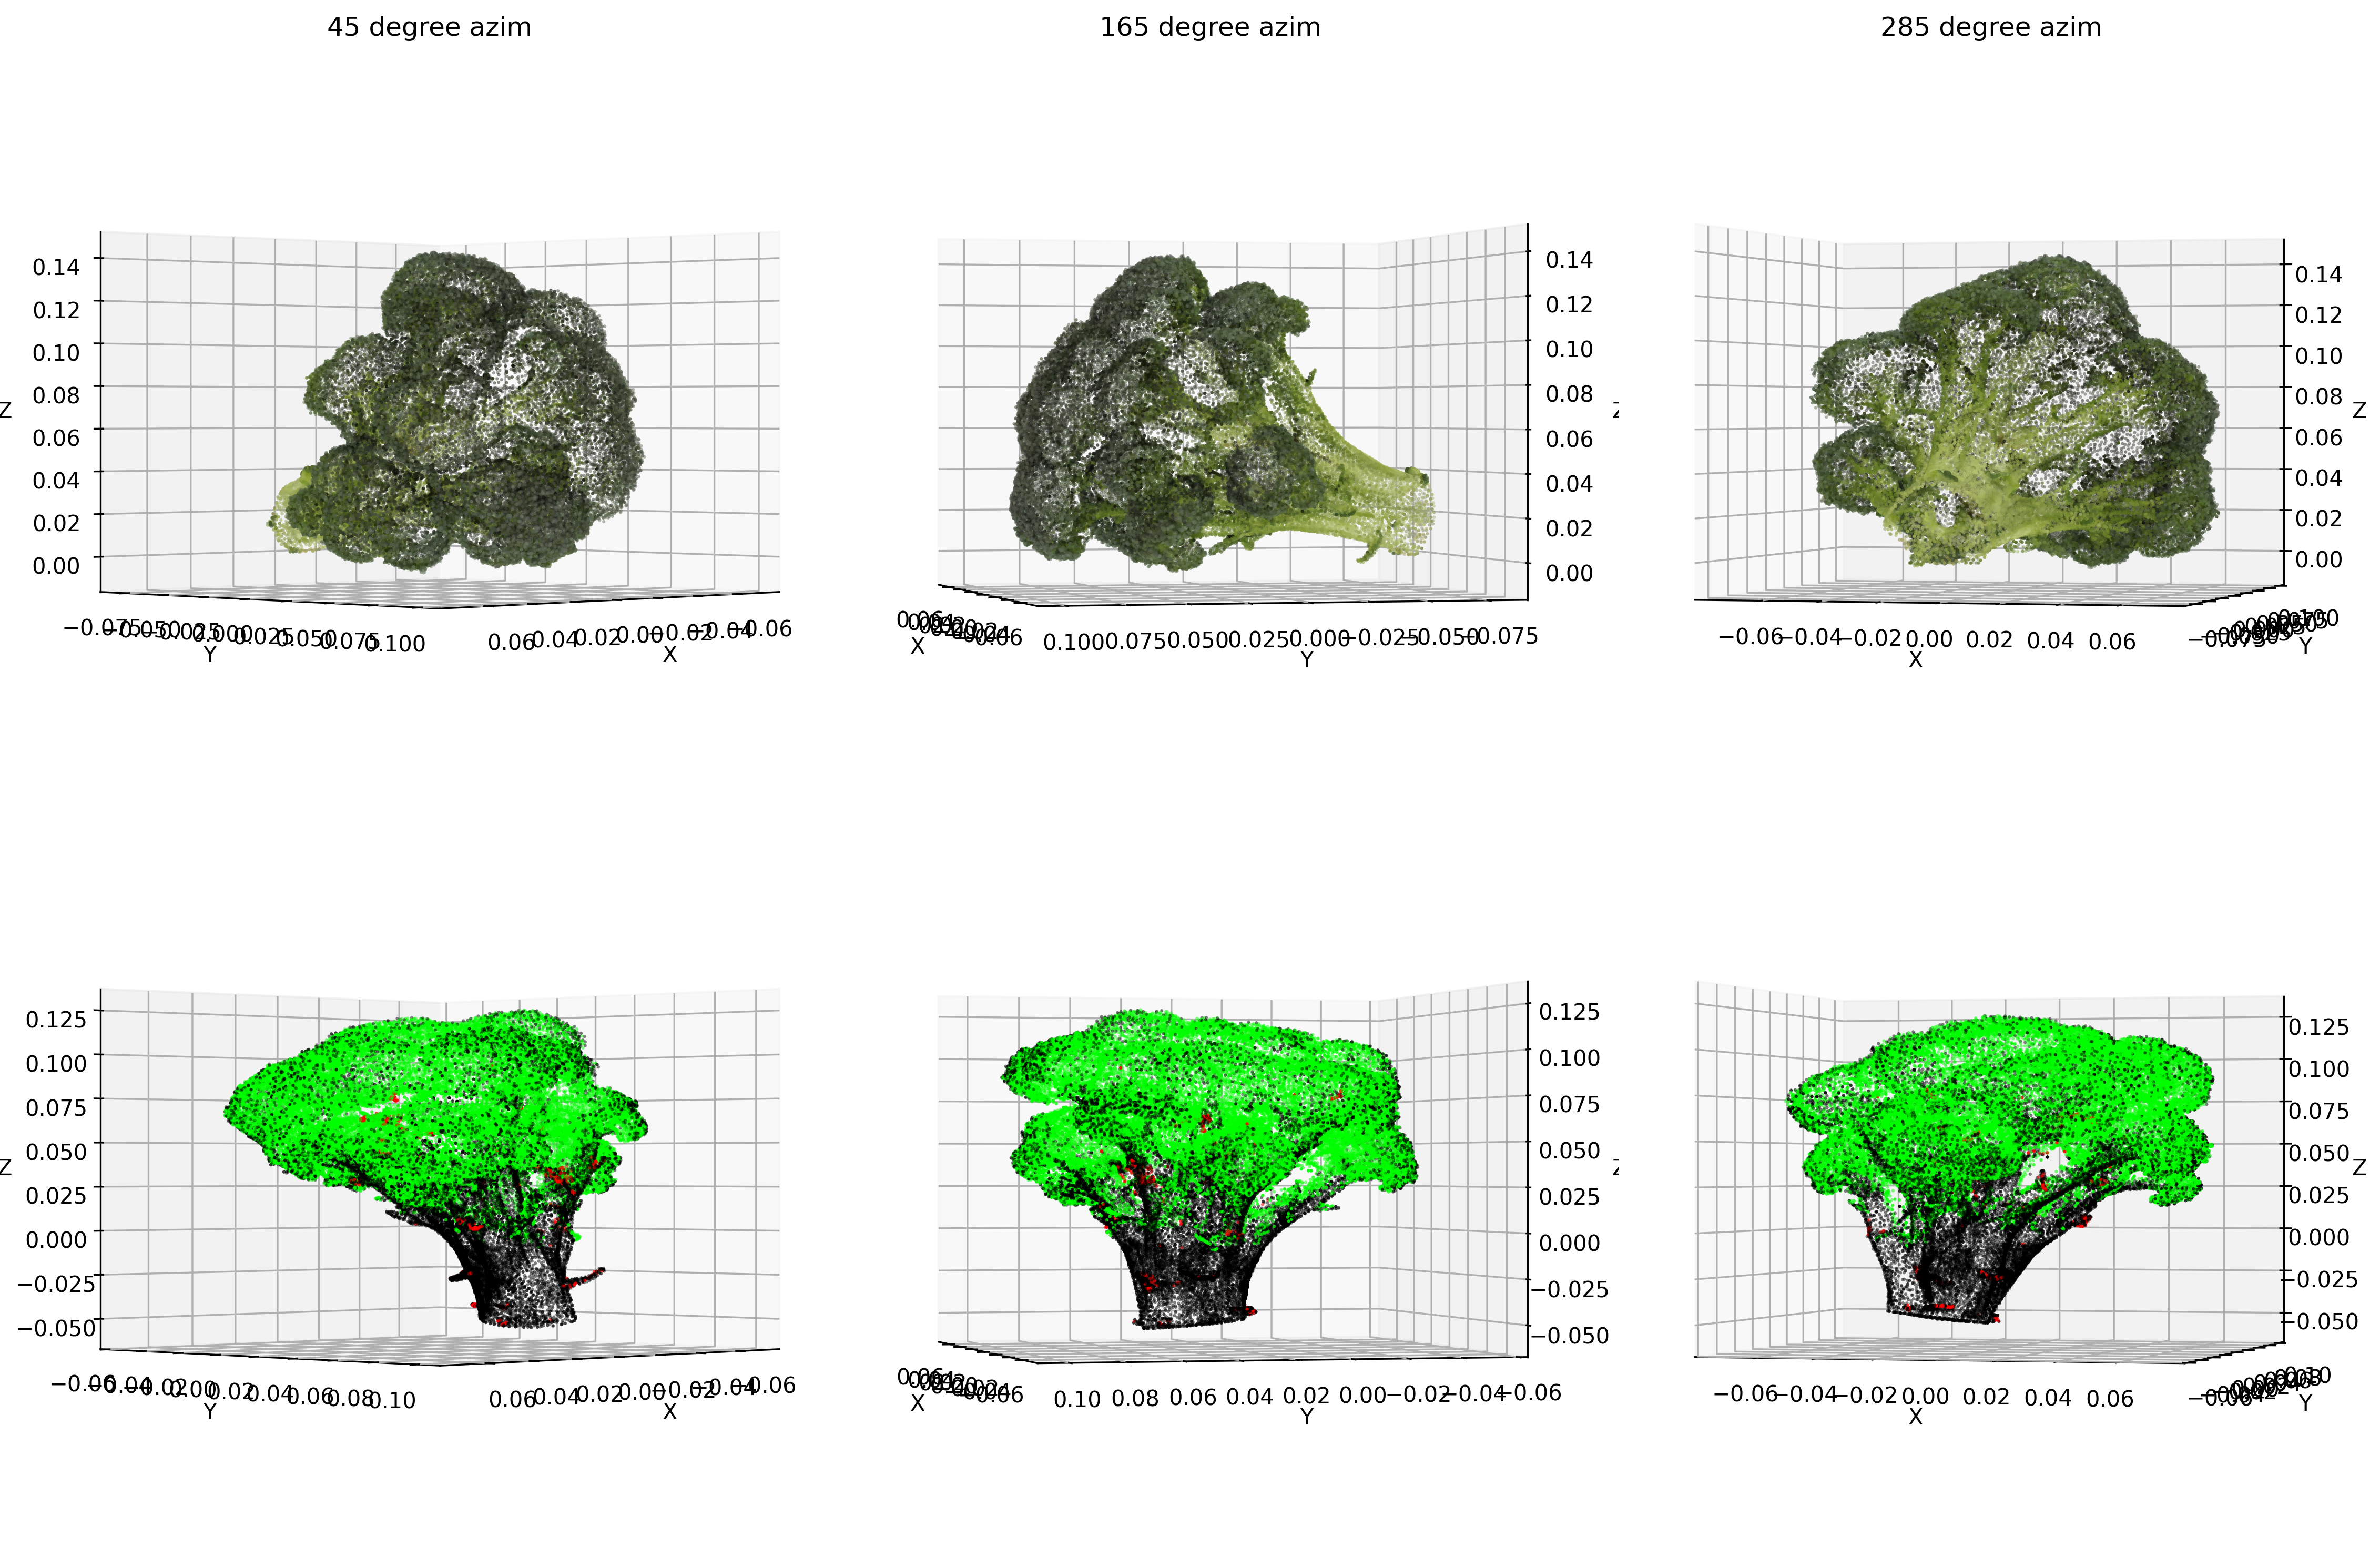

In [80]:
broccoli_id = 190

def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(mesh_db[broccoli_id]))

crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd = rotate_to_z(crown_pcd, def_test_pcd, vz)

# draw figures
xyz_o = np.asarray(def_test_pcd.points)
rgb_o = np.asarray(def_test_pcd.colors)

xyz = np.asarray(rotated_pcd.points)
rgb = np.asarray(crown_colored_pcd.colors)


fig = plt.figure(figsize=(15, 10), dpi=300)
ax1 = fig.add_subplot(231, projection='3d')
ax2 = fig.add_subplot(232, projection='3d')
ax3 = fig.add_subplot(233, projection='3d')
ax4 = fig.add_subplot(234, projection='3d')
ax5 = fig.add_subplot(235, projection='3d')
ax6 = fig.add_subplot(236, projection='3d')

for ax in [ax1, ax2, ax3]:
    ax.scatter(*xyz_o.T, c=rgb_o, marker='.', alpha=0.5, s=1)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

for ax in [ax4, ax5, ax6]:
    ax.scatter(*xyz.T, c=rgb, marker='.', alpha=0.5, s=1)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

ax1.view_init(elev=0, azim=45)
ax2.view_init(elev=0, azim=165)
ax3.view_init(elev=0, azim=285)
ax4.view_init(elev=0, azim=45)
ax5.view_init(elev=0, azim=165)
ax6.view_init(elev=0, azim=285)

ax1.set_title('45 degree azim')
ax2.set_title('165 degree azim')
ax3.set_title('285 degree azim')

plt.tight_layout()
plt.savefig(f"out/{broccoli_id}_rot_seg.png")
plt.show()

In [1]:
def draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, save_path):
    fig = plt.figure(figsize=(15, 10), dpi=300)
    ax1 = fig.add_subplot(231, projection='3d')
    ax2 = fig.add_subplot(232, projection='3d')
    ax3 = fig.add_subplot(233, projection='3d')
    ax4 = fig.add_subplot(234, projection='3d')
    ax5 = fig.add_subplot(235, projection='3d')
    ax6 = fig.add_subplot(236, projection='3d')

    for ax in [ax1, ax2, ax3]:
        ax.scatter(*xyz_o.T, c=rgb_o, marker='.', alpha=0.5, s=1)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')

    for ax in [ax4, ax5, ax6]:
        ax.scatter(*xyz_r.T, c=rgb_r, marker='.', alpha=0.5, s=1)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')

    ax1.view_init(elev=0, azim=45)
    ax2.view_init(elev=0, azim=165)
    ax3.view_init(elev=0, azim=285)
    ax4.view_init(elev=0, azim=45)
    ax5.view_init(elev=0, azim=165)
    ax6.view_init(elev=0, azim=285)

    ax1.set_title('45 degree azim')
    ax2.set_title('165 degree azim')
    ax3.set_title('285 degree azim')

    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()